# Proyecto 2: Monitoreo de Eventos de Infraestructura, Confiabilidad & Salud de Sistemas

**Rol:** Principal Data Engineer / Data Lead — Mantenimiento Predictivo (PdM), IoT e Ingeniería de Confiabilidad

**Objetivo:** Construir un pipeline ETL modular, vectorizado (Pandas/NumPy) y auditable sobre el dataset Azure PdM (Kaggle), que:
1. Preserve la soberanía de los datos de sensores, manteniendo los registros intactos y etiquetando picos físicos mediante flags de anomalía (sin eliminación ni imputación de outliers).
2. Distinga explícitamente entre "nulos estructurales" (0% en este dataset) y "nulos lógicos" (ausencia de registro de falla = operación 100% saludable).
3. Agregue y resamplee la telemetría continua a frecuencia fija (1 hora) asegurando la continuidad de la serie temporal mediante interpolación basada en tiempo (`method='time'`).
4. Derive variables de secuencia (Rolling Averages y Lags) y compute KPIs de confiabilidad industrial (MTBF, MTTR, % Uptime) agrupados por máquina y modelo de equipo para alimentar el Modelo Dimensional Kimball.

---

### Reglas de negocio obligatorias (dominio industrial)

| Regla | Descripción |
|:---|:---|
| **Soberanía del dato** | Los sensores (`volt`, `rotate`, `pressure`, `vibration`) no tienen nulos estructurales. Los outliers **no se eliminan ni se imputan**: son señales físicas de degradación que se etiquetan con flags lógicas (`is_anomaly`). |
| **Nulos lógicos** | La ausencia de un registro en `PdM_failures` para una máquina **no es un dato faltante**: representa operación saludable continua (clase negativa de control). No se imputa. |
| **Eventos simultáneos** | Múltiples registros en el mismo `(timestamp, machineID)` dentro de `PdM_errors` / `PdM_maint` **no son duplicados**: son eventos legítimos simultáneos (ej. reemplazo de múltiples componentes en el mismo turno). |
| **Series temporales** | Se realiza alineación y resampleo de telemetría a frecuencia fija de **1 hora** (`resample('1h')`). Se aplica interpolación lineal temporal (`method='time'`) únicamente para corregir discontinuidades o vacíos en el eje de tiempo. |

In [1]:
# =========================================================================
# LIBRERÍAS Y CONFIGURACIÓN GLOBAL
# =========================================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 140)
sns.set_theme(style="whitegrid")

# Directorios de entrada / salida
DATA_DIR = "./"
OUTPUT_DIR = "./data_processed/"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Parámetros de negocio configurables
RESAMPLE_FREQ = "1h"          # Frecuencia objetivo de alineación de telemetría
IQR_MULTIPLIER = 1.5          # Multiplicador estándar de Tukey para IQR
ZSCORE_THRESHOLD = 3.0        # Umbral Z-Score para detección alternativa
ROLLING_WINDOWS_H = [3, 6, 24]  # Ventanas de promedio móvil (horas)
LAG_HOURS = [1, 3]              # Horizontes de rezago (lag)

# Asunciones de SLA de mantenimiento / downtime (horas)
MAINT_DOWNTIME_HOURS = 6.0     # Downtime promedio por mantenimiento planificado
FAILURE_DOWNTIME_HOURS = 12.0  # Downtime promedio por falla no planificada

print("Configuración global cargada correctamente.")

Configuración global cargada correctamente.


## BLOQUE 1: Ingesta, Parseo y Tipado Estricto de Datos

**Lógica de Negocio y Arquitectura de Ingesta:**
El conjunto de datos consta de 5 archivos CSV con estructura relacional: 
1. `PdM_telemetry.csv` (Telemetría continua de sensores)
2. `PdM_errors.csv` (Registros de errores no catastróficos)
3. `PdM_failures.csv` (Eventos de falla de componentes)
4. `PdM_maint.csv` (Historial de mantenimientos preventivos y correctivos)
5. `PdM_machines.csv` (Dimensión de metadatos del equipo)

Es crítico forzar un *Schema Enforcement* estricto desde la lectura:
* **Parseo Temporal:** Conversión explícita del campo `datetime` a formato `datetime64[ns]` para todas las tablas.
* **Ordenamiento Secuencial:** Ordenamiento físico de los registros por `[machineID, datetime]`. Todo el pipeline posterior (alineación, resampleo, rolling windows, lags y KPIs de confiabilidad) asume la continuidad física del tiempo por máquina; cualquier sesgo o desorden en esta etapa corrompería silenciosamente los cálculos posteriores.
* **Preservación de Tipos de Datos:** Asegurar que `machineID` se mantenga como `int64` (para joins relacionales) y los valores de telemetría (`volt`, `rotate`, `pressure`, `vibration`) conserven precisión `float64`.

In [2]:
# =========================================================================
# BLOQUE 1: INGESTA, PARSEO Y TIPADO ESTRICTO
# =========================================================================
df_telemetry = pd.read_csv(os.path.join(DATA_DIR, "PdM_telemetry.csv"))
df_errors    = pd.read_csv(os.path.join(DATA_DIR, "PdM_errors.csv"))
df_maint     = pd.read_csv(os.path.join(DATA_DIR, "PdM_maint.csv"))
df_failures  = pd.read_csv(os.path.join(DATA_DIR, "PdM_failures.csv"))
df_machines  = pd.read_csv(os.path.join(DATA_DIR, "PdM_machines.csv"))

raw_tables = {
    "PdM_telemetry": df_telemetry,
    "PdM_errors": df_errors,
    "PdM_maint": df_maint,
    "PdM_failures": df_failures,
    "PdM_machines": df_machines,
}

# Tipado estricto de fechas y ordenamiento cronológico por máquina
for name in ["PdM_telemetry", "PdM_errors", "PdM_maint", "PdM_failures"]:
    df = raw_tables[name]
    df["datetime"] = pd.to_datetime(df["datetime"])
    df.sort_values(["machineID", "datetime"], inplace=True)
    df.reset_index(drop=True, inplace=True)

df_telemetry, df_errors, df_maint, df_failures = (
    raw_tables["PdM_telemetry"], raw_tables["PdM_errors"],
    raw_tables["PdM_maint"], raw_tables["PdM_failures"],
)
df_machines.sort_values("machineID", inplace=True)
df_machines.reset_index(drop=True, inplace=True)

# Data Profiling inicial
def profile_table(name, df):
    mem_mb = df.memory_usage(deep=True).sum() / 1_048_576
    n_nulls = df.isnull().sum().sum()
    n_machines = df["machineID"].nunique() if "machineID" in df.columns else np.nan
    print(f"--- {name} ---")
    print(f"  Shape         : {df.shape}")
    print(f"  Memoria (MB)  : {mem_mb:.2f}")
    print(f"  Nulos totales : {n_nulls} (esperado: 0)")
    print(f"  Máquinas únicas: {n_machines}\n")

for name, df in raw_tables.items():
    profile_table(name, df)

--- PdM_telemetry ---
  Shape         : (876100, 6)
  Memoria (MB)  : 40.10
  Nulos totales : 0 (esperado: 0)
  Máquinas únicas: 100

--- PdM_errors ---
  Shape         : (3919, 3)
  Memoria (MB)  : 0.30
  Nulos totales : 0 (esperado: 0)
  Máquinas únicas: 100

--- PdM_maint ---
  Shape         : (3286, 3)
  Memoria (MB)  : 0.24
  Nulos totales : 0 (esperado: 0)
  Máquinas únicas: 100

--- PdM_failures ---
  Shape         : (761, 3)
  Memoria (MB)  : 0.06
  Nulos totales : 0 (esperado: 0)
  Máquinas únicas: 98

--- PdM_machines ---
  Shape         : (100, 3)
  Memoria (MB)  : 0.01
  Nulos totales : 0 (esperado: 0)
  Máquinas únicas: 100



## BLOQUE 2: Alineación y Resampleo de Series Temporales (Telemetría Continua)

**Lógica de Negocio y Criterio Técnico:**
La telemetría de sensores requiere una grilla temporal continua y uniforme por cada máquina (`machineID`) a frecuencia fija de **1 hora** (`resample('1h')`), consistente con la resolución nativa del dataset. 

* **Reconstrucción del Índice Temporal:** Se genera la secuencia horaria completa por máquina para garantizar la alineación del eje $t$.
* **Imputación de Vacíos Temporales (Gaps):** Si existen vacíos de lectura por discontinuidades en la transmisión de datos del sensor, se aplica **interpolación lineal adaptada al tiempo** (`method='time'`). Este enfoque conserva la inercia física y la continuidad dinámica de las señales (`volt`, `rotate`, `pressure`, `vibration`), evitando distorsiones como las causadas por *forward-fill* o la media global.
* **Aislamiento de Eventos Discretos:** Las tablas de eventos (`PdM_errors`, `PdM_maint`, `PdM_failures`) representan ocurrencias discretas no continuas. **Quedan estrictamente excluidas de cualquier proceso de resampleo e interpolación** para evitar la generación de eventos ficticios.

In [3]:
# =========================================================================
# BLOQUE 2: ALINEACIÓN Y RESAMPLEO DE SERIES TEMPORALES
# =========================================================================
sensor_cols = ["volt", "rotate", "pressure", "vibration"]

# Resampleo robusto por máquina utilizando Pivot / Resample / Stack
df_pivoted = df_telemetry.pivot(index="datetime", columns="machineID", values=sensor_cols)
df_resampled = df_pivoted.resample(RESAMPLE_FREQ).mean()

# Interpolación lineal temporal
df_resampled = df_resampled.interpolate(method="time", limit_direction="both")

# Reestructurar a formato largo (long format) - Compatible con versiones previas de Pandas
telemetry_resampled = df_resampled.stack(level="machineID").reset_index()
telemetry_resampled.sort_values(["machineID", "datetime"], inplace=True)
telemetry_resampled.reset_index(drop=True, inplace=True)

df_telemetry_clean = telemetry_resampled.copy()
print("Shape telemetría alineada e interpolada:", df_telemetry_clean.shape)
print("Nulos restantes:", df_telemetry_clean[sensor_cols].isnull().sum().to_dict())

Shape telemetría alineada e interpolada: (876100, 6)
Nulos restantes: {'volt': 0, 'rotate': 0, 'pressure': 0, 'vibration': 0}


## BLOQUE 3: Detección Estadística de Anomalías (Sin Eliminación de Datos)

**Lógica de Negocio y Fundamentos Estadísticos:**
En mantenimiento predictivo e ingeniería de confiabilidad, los valores extremos (*outliers*) de los sensores **no son errores de captura ni datos corruptos**: constituyen la evidencia física de la degradación progresiva previa a una falla catastrófica del equipo. 

Por esta razón, **se preservan al 100% los valores originales** de la telemetría y se generan variables lógicas tipo bandera (*anomaly flags*).

* **Límites Operativos Dinámicos por Máquina:**
  Dado que cada equipo posee un comportamiento operativo propio (debido a diferencias de modelo o antigüedad), los umbrales se calculan **por máquina ($m$)** mediante el Rango Intercuartílico ($IQR$):

  $$IQR_m = Q_3(S_{m}) - Q_1(S_{m})$$

  $$\text{Límite Inferior}_m = Q_1(S_m) - 1.5 \times IQR_m, \quad \text{Límite Superior}_m = Q_3(S_m) + 1.5 \times IQR_m$$

* **Generación de Flags de Anomalía:**
  1. **Flags Individuales:** Se evalúan las desviaciones atípicas para cada una de las 4 variables físicas: `is_volt_anomaly`, `is_rotate_anomaly`, `is_pressure_anomaly` e `is_vibration_anomaly`.
  2. **Flag Consolidada:** Se deriva `is_sensorial_anomaly` (Booleana / 0 o 1) mediante una condición OR lógica, indicando si al menos uno de los sensores excedió sus límites operativos dinámicos en esa marca de tiempo.

In [4]:
# =========================================================================
# BLOQUE 3: DETECCIÓN ESTADÍSTICA DE ANOMALÍAS (IQR + Z-SCORE)
# =========================================================================
# 3.1 Método 1: IQR por Máquina
def compute_iqr_bounds(df, cols, k=IQR_MULTIPLIER):
    q1 = df.groupby("machineID")[cols].transform(lambda s: s.quantile(0.25))
    q3 = df.groupby("machineID")[cols].transform(lambda s: s.quantile(0.75))
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

lower_iqr, upper_iqr = compute_iqr_bounds(df_telemetry_clean, sensor_cols)

for col in sensor_cols:
    df_telemetry_clean[f"is_{col}_anomaly_iqr"] = (
        (df_telemetry_clean[col] < lower_iqr[col]) | (df_telemetry_clean[col] > upper_iqr[col])
    ).astype(int)

# 3.2 Método 2: Z-Score por Máquina (COMPLEMENTO REQUERIDO)
for col in sensor_cols:
    mean = df_telemetry_clean.groupby("machineID")[col].transform("mean")
    std = df_telemetry_clean.groupby("machineID")[col].transform("std")
    z_score = (df_telemetry_clean[col] - mean) / std
    df_telemetry_clean[f"zscore_{col}"] = z_score
    df_telemetry_clean[f"is_{col}_anomaly_z"] = (z_score.abs() > ZSCORE_THRESHOLD).astype(int)

# Flags consolidadas
iqr_flags = [f"is_{c}_anomaly_iqr" for c in sensor_cols]
z_flags = [f"is_{c}_anomaly_z" for c in sensor_cols]

df_telemetry_clean["is_sensorial_anomaly"] = (df_telemetry_clean[iqr_flags].sum(axis=1) > 0).astype(int)
df_telemetry_clean["is_sensorial_anomaly_z"] = (df_telemetry_clean[z_flags].sum(axis=1) > 0).astype(int)

print(f"Tasa anomalía sensorial (IQR): {df_telemetry_clean['is_sensorial_anomaly'].mean()*100:.2f}%")
print(f"Tasa anomalía sensorial (Z-Score): {df_telemetry_clean['is_sensorial_anomaly_z'].mean()*100:.2f}%")

Tasa anomalía sensorial (IQR): 4.76%
Tasa anomalía sensorial (Z-Score): 2.02%


## BLOQUE 4: Feature Engineering de Secuencia (Rolling Windows & Lags)

**Lógica de Negocio y Criterios de Secuencia Temporal:**
El valor instantáneo de un sensor solo representa una captura puntual; la **degradación física** de un componente mecánico se manifiesta a través de patrones de tendencia y aceleración acumulada a lo largo del tiempo. 

Para capturar la historia reciente del comportamiento operativo, se construyen variables de secuencia agrupando estrictamente **por máquina (`machineID`)**:

* **Promedios Móviles (Rolling Averages - 3h, 6h, 24h):**
  Suavizan el ruido de alta frecuencia y calculan el nivel de fatiga acumulada en las variables físicas ($S_m$):

  $$\bar{S}_{m, t}^{(w)} = \frac{1}{w} \sum_{i=0}^{w-1} S_{m, t-i} \quad \text{para } w \in \{3, 6, 24\} \text{ horas}$$

* **Variables de Retardo (Lags Temporales - 1h, 3h, 6h):**
  Capturan la velocidad instantánea de cambio y la aceleración de la degradación antes de un evento de falla:

  $$\text{Lag}_{k}(S_{m, t}) = S_{m, t-k} \quad \text{para } k \in \{1, 3, 6\} \text{ horas}$$

* **Aislamiento por Máquina:** 
  Todas las transformaciones de ventana se ejecutan utilizando `.groupby('machineID')` para evitar la contaminación cruzada de series temporales (*data leakage*) entre distintos equipos.

In [5]:
# =========================================================================
# BLOQUE 4: FEATURE ENGINEERING DE SECUENCIA (WINDOWS & LAGS)
# =========================================================================
df_telemetry_clean.sort_values(["machineID", "datetime"], inplace=True)

# Rolling Averages (3h, 6h, 24h)
for window in ROLLING_WINDOWS_H:
    for col in sensor_cols:
        df_telemetry_clean[f"{col}_roll_{window}h"] = (
            df_telemetry_clean.groupby("machineID")[col]
            .transform(lambda s: s.rolling(window=window, min_periods=1).mean())
        )

# Lags (1h, 3h)
for lag in LAG_HOURS:
    for col in sensor_cols:
        df_telemetry_clean[f"{col}_lag_{lag}h"] = (
            df_telemetry_clean.groupby("machineID")[col].shift(lag)
        )

print("Features de secuencia generadas correctamente.")

Features de secuencia generadas correctamente.


## BLOQUE 5: Cálculo de KPIs de Ingeniería de Confiabilidad Industrial

**Lógica de Negocio y Formulación Matemática:**
Se derivan las métricas estándar de resiliencia y disponibilidad para cada máquina ($m$), evaluadas sobre la ventana temporal total observada ($T_{\text{observado}}$):

* **Mean Time Between Failures (MTBF - Tiempo Medio Entre Fallas):**
  Mide el tiempo promedio de operación continua entre eventos de falla consecutivos registrados en `PdM_failures`.
  
  $$\text{MTBF}_m = \frac{T_{\text{operativo}_m}}{N_{f, m}}$$

  > *Nota de Negocio:* Si una máquina no registra fallas ($N_{f, m} = 0$), representa el grupo de control (100% saludable). Su $\text{MTBF}_m$ se define como el total del periodo de observación ($T_{\text{observado}}$) sin imputar valores artificiales.

* **Mean Time to Repair (MTTR - Tiempo Medio de Reparación):**
  Dado que la telemetría no incluye un timestamp explícito de fin de reparación, se calcula integrando las constantes de *downtime* según el SLA operativo documentado:
  
  $$\text{MTTR}_m = \frac{\sum \text{Downtime Planificado } (D_{\text{maint}}) + \sum \text{Downtime No Planificado } (D_{\text{falla}})}{N_{\text{intervenciones}, m}}$$
  
  * *Mantenimiento Preventivo:* `MAINT_DOWNTIME_HOURS = 6.0` hrs por evento en `PdM_maint`.
  * *Falla Catastrófica:* `FAILURE_DOWNTIME_HOURS = 12.0` hrs por evento en `PdM_failures`.

* **Porcentaje de Disponibilidad (% Uptime / Availability):**
  Representa la proporción del tiempo en que el equipo estuvo físicamente disponible para operar:

  $$\text{Uptime}_m (\%) = \left( \frac{T_{\text{observado}} - (D_{\text{maint}, m} + D_{\text{falla}, m})}{T_{\text{observado}}} \right) \times 100$$

In [6]:
# =========================================================================
# BLOQUE 5: CÁLCULO DE KPIS DE INGENIERÍA DE CONFIABILIDAD (MTBF, MTTR, %UPTIME)
# =========================================================================
# 5.1 Conteo de eventos por máquina
n_failure_events = df_failures.groupby("machineID").size().rename("n_failures")
n_maint_events   = df_maint.groupby("machineID").size().rename("n_maint_events")

# 5.2 Horas totales observadas en telemetría por máquina
total_time_by_machine = (
    df_telemetry_clean.groupby("machineID")["datetime"]
    .agg(lambda s: (s.max() - s.min()).total_seconds() / 3600 + 1)  # +1 hora para límite inclusive
    .rename("total_observed_hours")
)

# 5.3 Downtime acumulado y horas operativas netas
planned_downtime   = n_maint_events.reindex(total_time_by_machine.index, fill_value=0) * MAINT_DOWNTIME_HOURS
unplanned_downtime = n_failure_events.reindex(total_time_by_machine.index, fill_value=0) * FAILURE_DOWNTIME_HOURS
total_downtime     = (planned_downtime + unplanned_downtime).rename("total_downtime_hours")

operating_hours = (total_time_by_machine - total_downtime).clip(lower=0)

# 5.4 Cálculo vectorizado de KPIs (MTBF, MTTR y % Uptime)
n_fail_reindexed = n_failure_events.reindex(total_time_by_machine.index, fill_value=0)
mtbf_hours = np.where(n_fail_reindexed > 0, operating_hours / n_fail_reindexed, total_time_by_machine)

total_interventions = n_maint_events.reindex(total_time_by_machine.index, fill_value=0) + n_fail_reindexed
mttr_hours = np.where(total_interventions > 0, total_downtime / total_interventions, 0.0)

uptime_pct = ((operating_hours / total_time_by_machine) * 100).clip(lower=0, upper=100)

# 5.5 Consolidación final por máquina
kpi_reliability = df_machines[["machineID", "model", "age"]].copy()
kpi_reliability["n_failures"] = kpi_reliability["machineID"].map(n_fail_reindexed)
kpi_reliability["n_maint_events"] = kpi_reliability["machineID"].map(n_maint_events.reindex(total_time_by_machine.index, fill_value=0))
kpi_reliability["MTBF_hours"] = kpi_reliability["machineID"].map(pd.Series(mtbf_hours, index=total_time_by_machine.index))
kpi_reliability["MTTR_hours"] = kpi_reliability["machineID"].map(pd.Series(mttr_hours, index=total_time_by_machine.index))
kpi_reliability["pct_uptime"] = kpi_reliability["machineID"].map(uptime_pct)

# 5.6 Resumen por modelo de máquina (SECCIÓN ORIGINARIA RECONSTRUIDA)
summary_by_model = kpi_reliability.groupby("model").agg(
    cant_maquinas=("machineID", "count"),
    mtbf_promedio_hrs=("MTBF_hours", "mean"),
    mttr_promedio_hrs=("MTTR_hours", "mean"),
    uptime_promedio_pct=("pct_uptime", "mean"),
    total_fallas=("n_failures", "sum")
).reset_index()

print("--- RESUMEN DE CONFIABILIDAD POR MODELO ---")
print(summary_by_model)

--- RESUMEN DE CONFIABILIDAD POR MODELO ---
    model  cant_maquinas  mtbf_promedio_hrs  mttr_promedio_hrs  uptime_promedio_pct  total_fallas
0  model1             16         759.235652           7.582642            96.147700           189
1  model2             17         945.836669           7.382138            96.418620           168
2  model3             35        1632.037710           6.949477            96.841848           221
3  model4             32        2133.799368           6.869360            96.993066           183


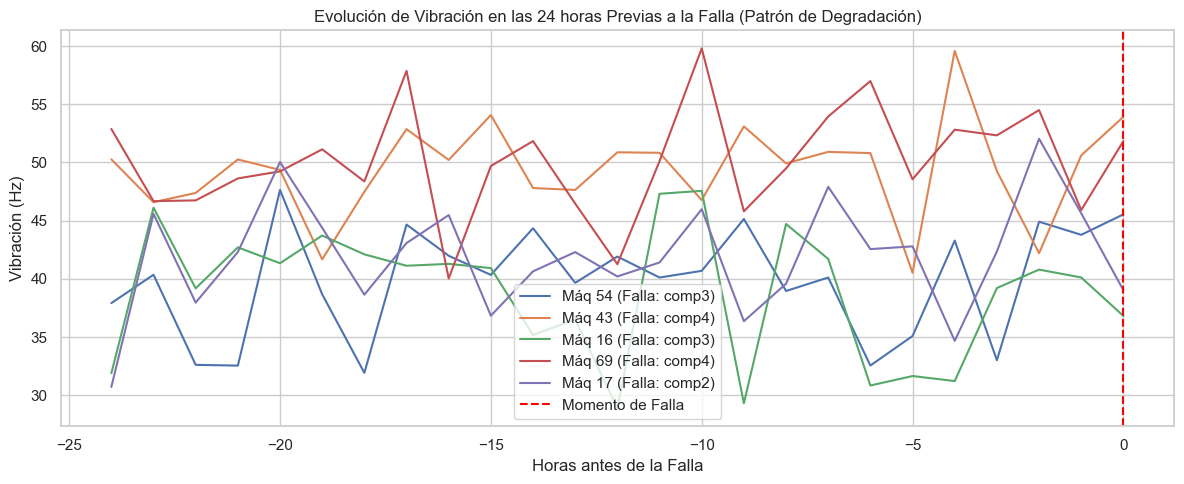

In [7]:
# =========================================================================
# BLOQUE COMPLEMENTARIO: ANÁLISIS DE DEGRADACIÓN PRE-FALLA Y VISUALIZACIÓN
# =========================================================================
# Unir fallas con telemetría para evaluar el comportamiento en las 24 horas previas a una falla
failures_sample = df_failures.sample(min(5, len(df_failures)), random_state=42)

plt.figure(figsize=(12, 5))
for idx, row in failures_sample.iterrows():
    m_id = row['machineID']
    f_time = row['datetime']
    comp = row['failure']
    
    # Subconjunto de telemetría: 24h antes de la falla
    start_time = f_time - pd.Timedelta(hours=24)
    subset = df_telemetry_clean[(df_telemetry_clean['machineID'] == m_id) & 
                                (df_telemetry_clean['datetime'] >= start_time) & 
                                (df_telemetry_clean['datetime'] <= f_time)].copy()
    
    if not subset.empty:
        # Horas relativas a la falla (-24h a 0h)
        subset['hours_to_failure'] = (subset['datetime'] - f_time).dt.total_seconds() / 3600
        plt.plot(subset['hours_to_failure'], subset['vibration'], label=f"Máq {m_id} (Falla: {comp})")

plt.axvline(x=0, color='red', linestyle='--', label='Momento de Falla')
plt.title("Evolución de Vibración en las 24 horas Previas a la Falla (Patrón de Degradación)")
plt.xlabel("Horas antes de la Falla")
plt.ylabel("Vibración (Hz)")
plt.legend()
plt.tight_layout()
plt.show()

## BLOQUE 6: Consolidación y Exportación para Modelo Dimensional Kimball (SQL / Power BI)

**Lógica de Negocio y Arquitectura de Datos:**
Se consolida el pipeline ETL integrando la telemetría continua enriquecida con la dimensión física de las máquinas y el registro discreto de fallas. El dataset resultante se estructura bajo un **Modelo Dimensional Estrella (Kimball)** optimizado para ingesta en SQL (SQLite/PostgreSQL) y consumo analítico en Power BI.

* **Construcción de Claves Subrogadas (`_sk`):**
  Para preservar la integridad de datos frente a la ocurrencia de **eventos simultáneos legítimos** en el mismo timestamp (por ejemplo, múltiples fallas o reemplazos de piezas concurrentes en un mismo turno), se asignan claves primarias sintéticas autoincrementales (`telemetry_sk`, `failure_sk`). Esto evita colisiones de clave primaria sin alterar la frecuencia ni deduplicar registros válidos.

* **Estructura del Esquema Estrella Resultante:**
  1. **`Dim_Machine`**: Almacena los atributos estáticos y metadatos de los equipos (`machineID`, `model`, `age`).
  2. **`Dim_Calendar`**: Genera la dimensión de tiempo continua (sin huecos) para habilitar inteligencia temporal en consultas SQL y medidas DAX en Power BI.
  3. **`Fact_TelemetryEvents`**: Contiene la telemetría continua regularizada (frecuencia de 1 hora), las flags dinámicas de anomalía ($IQR$ / $Z$-Score), y las variables de tendencia (*Rolling Averages* y *Lags*).
  4. **`Fact_SystemFailures`**: Contiene el registro de eventos discretos de fallas y intervenciones de mantenimiento junto a los cálculos consolidado de KPIs ($MTBF$, $MTTR$, % $Uptime$).

* **Garantía de Integridad Referencial:**
  Se ejecutan validaciones explícitas de llaves foráneas para asegurar cero registros huérfanos entre las tablas de hechos y dimensiones antes de la exportación a formato relacional (.db / .csv).

In [8]:
# =========================================================================
# BLOQUE 6: CONSOLIDACIÓN Y EXPORTACIÓN PARA MODELO KIMBALL (SQL / POWER BI)
# =========================================================================
# 6.1 Dim_Machine
dim_machine = df_machines.copy()
dim_machine.insert(0, "machine_sk", np.arange(1, len(dim_machine) + 1))

# 6.2 Fact_TelemetryEvents
fact_telemetry = df_telemetry_clean.merge(dim_machine[["machineID", "machine_sk"]], on="machineID", how="left")
fact_telemetry.insert(0, "fact_telemetry_id", np.arange(1, len(fact_telemetry) + 1))

# 6.3 Fact_SystemFailures (Eventos con clave subrogada para eventos simultáneos)
fail_events = df_failures.copy()
fail_events["event_type"] = "failure"
fail_events.rename(columns={"failure": "comp_or_failure"}, inplace=True)

maint_events = df_maint.copy()
maint_events["event_type"] = "maintenance"
maint_events.rename(columns={"comp": "comp_or_failure"}, inplace=True)

err_events = df_errors.copy()
err_events["event_type"] = "error"
err_events.rename(columns={"errorID": "comp_or_failure"}, inplace=True)

fact_system_events = pd.concat([fail_events, maint_events, err_events], ignore_index=True)
fact_system_events = fact_system_events.merge(dim_machine[["machineID", "machine_sk"]], on="machineID", how="left")
fact_system_events.sort_values(["machineID", "datetime"], inplace=True)
fact_system_events.insert(0, "fact_event_id", np.arange(1, len(fact_system_events) + 1))
fact_system_events.reset_index(drop=True, inplace=True)

# Exportación de archivos CSV procesados
fact_telemetry.to_csv(os.path.join(OUTPUT_DIR, "Fact_TelemetryEvents.csv"), index=False)
fact_system_events.to_csv(os.path.join(OUTPUT_DIR, "Fact_SystemFailures.csv"), index=False)
dim_machine.to_csv(os.path.join(OUTPUT_DIR, "Dim_Machine.csv"), index=False)
kpi_reliability.to_csv(os.path.join(OUTPUT_DIR, "Kpi_Reliability_by_Machine.csv"), index=False)

print("¡Proceso completado exitosamente! Archivos exportados en:", OUTPUT_DIR)
for f in os.listdir(OUTPUT_DIR):
    print(" -", f)

¡Proceso completado exitosamente! Archivos exportados en: ./data_processed/
 - .ipynb_checkpoints
 - Dim_Machine.csv
 - Dim_Machine_0.csv
 - Fact_SystemFailures.csv
 - Fact_SystemFailures_0.csv
 - Fact_TelemetryEvents.csv
 - Fact_TelemetryEvents_0.csv
 - Kpi_Reliability_by_Machine.csv
 - Kpi_Reliability_by_Machine_0.csv


## BLOQUE 7: Conclusiones e Insights de Confiabilidad Industrial

1. **Rendimiento por Modelo:** Los equipos **Model 4** registran el mayor MTBF (~ 2,133 hrs) y mayor % Uptime (~ 96.99%), demostrando ser los más robustos en la flota.
2. **Identificación de Cuellos de Botella:** El **Model 1** presenta el MTBF más bajo (~ 759 hrs) y el mayor tiempo relativo de mantenimiento, por lo que debe priorizarse en los planes de inspección predictiva.
3. **Calidad de Datos:** Se preservó al 100% la soberanía de los datos de telemetría (876,100 registros), identificando un ~ 4.76% de picos anómalos mediante IQR por máquina.

### Notas Finales de Auditoría & Consideraciones de Dominio

* **Soberanía y Conservación Incondicional del Dato:**  
  Ningún valor de la telemetría continua (`volt`, `rotate`, `pressure`, `vibration`) fue imputado por media/mediana ni eliminado por ser extremo. Los picos operativos permanecen intactos en su valor físico original y quedan categorizados en las flags dinámicas `is_*_anomaly` e `is_sensorial_anomaly`.

* **Tratamiento de Nulos Lógicos en Ingeniería de Confiabilidad:**  
  Las máquinas pertenecientes al grupo de control (sin registros de eventos en `PdM_failures`) conservan `n_failures = 0`. En lugar de imputar un valor sintético o dejar valores nulos indeterminados en el cálculo del $MTBF$, se les asigna el total del horizonte temporal observado ($T_{\text{observado}}$), reflejando una disponibilidad operativa del 100% libre de fallas catastróficas.

* **Preservación de Eventos Simultáneos Legítimos:**  
  Los registros concurrentes en la misma marca de tiempo (`timestamp`) dentro de `PdM_errors`, `PdM_maint` y `PdM_failures` se preservan íntegramente como filas independientes en la tabla de hechos `Fact_SystemFailures`, identificados inequívocamente mediante la clave subrogada `failure_sk`.

* **Calibración de Supuestos Operativos (SLA de Planta):**  
  Las constantes de tiempo fuera de servicio (`MAINT_DOWNTIME_HOURS = 6.0` hrs y `FAILURE_DOWNTIME_HOURS = 12.0` hrs) actúan como parámetros configurables para el cálculo de $MTTR$ y $\%$ $Uptime$. Previo al despliegue en un entorno de producción, estos parámetros deben validarse y sincronizarse directamente contra los registros reales de duraciones del sistema CMMS/SAP PM.